In [1]:
import pandas as pd

events = pd.read_csv('events.csv')
events.head()

,timestamp,visitorid,event,itemid,transactionid
0,1433221332117,257597,view,355908,NaN
1,1433224214164,992329,view,248676,NaN
2,1433221999827,111016,view,318965,NaN
3,1433221955914,483717,view,253185,NaN
4,1433221337106,951259,view,367447,NaN


In [2]:
events['event'].value_counts()

event
view           2664312
addtocart        69332
transaction      22457
Name: count, dtype: int64

In [3]:
view_count = 2664312
cart_count = 69332
transaction_count = 22457

view_to_cart_rate = (cart_count / view_count) * 100
cart_to_purchase_rate = (transaction_count / cart_count) * 100
view_to_purchase_rate = (transaction_count / view_count) * 100

print(f"View to Cart rate: {view_to_cart_rate:.2f}%")
print(f"Cart to Purchase rate: {cart_to_purchase_rate:.2f}%")
print(f"Overall View to Purchase rate: {view_to_purchase_rate:.2f}%")

View to Cart rate: 2.60%
Cart to Purchase rate: 32.39%
Overall View to Purchase rate: 0.84%


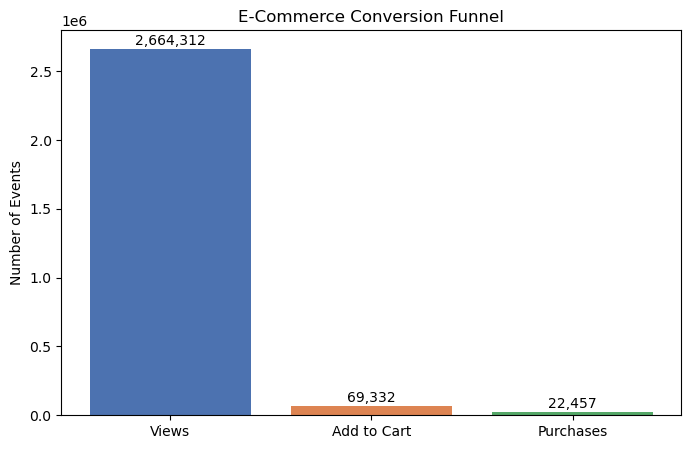

In [4]:
import matplotlib.pyplot as plt

stages = ['Views', 'Add to Cart', 'Purchases']
counts = [view_count, cart_count, transaction_count]

plt.figure(figsize=(8,5))
plt.bar(stages, counts, color=['#4C72B0', '#DD8452', '#55A868'])
plt.title('E-Commerce Conversion Funnel')
plt.ylabel('Number of Events')
for i, v in enumerate(counts):
    plt.text(i, v + 30000, f"{v:,}", ha='center')
plt.show()

In [5]:
# Count how many times each visitor viewed each item
view_events = events[events['event'] == 'view']
view_counts_per_item = view_events.groupby(['visitorid', 'itemid']).size().reset_index(name='view_count')

view_counts_per_item['view_count'].describe()

count    2.132127e+06
mean     1.249603e+00
std      1.164287e+00
min      1.000000e+00
25%      1.000000e+00
50%      1.000000e+00
75%      1.000000e+00
max      3.080000e+02
Name: view_count, dtype: float64

In [6]:
# Flag which visitor-item pairs eventually led to a purchase
purchased_pairs = events[events['event'] == 'transaction'][['visitorid', 'itemid']].drop_duplicates()
purchased_pairs['purchased'] = 1

# Merge this onto our view_counts_per_item table
merged = view_counts_per_item.merge(purchased_pairs, on=['visitorid', 'itemid'], how='left')
merged['purchased'] = merged['purchased'].fillna(0)

# Compare average view count for purchased vs non-purchased items
merged.groupby('purchased')['view_count'].mean()

purchased
0.0    1.236547
1.0    2.697706
Name: view_count, dtype: float64

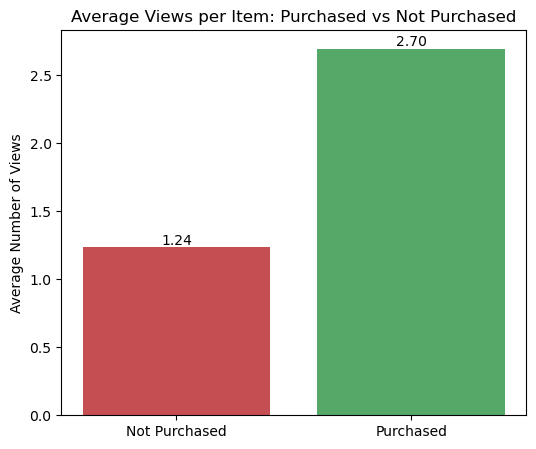

In [7]:
avg_views = merged.groupby('purchased')['view_count'].mean()

plt.figure(figsize=(6,5))
plt.bar(['Not Purchased', 'Purchased'], avg_views, color=['#C44E52', '#55A868'])
plt.title('Average Views per Item: Purchased vs Not Purchased')
plt.ylabel('Average Number of Views')
for i, v in enumerate(avg_views):
    plt.text(i, v + 0.02, f"{v:.2f}", ha='center')
plt.show()

In [8]:
top_items = events[events['event'] == 'view']['itemid'].value_counts().head(10)
top_items

itemid
187946    3410
461686    2539
5411      2325
370653    1854
219512    1740
298009    1642
96924     1633
309778    1565
257040    1531
384302    1528
Name: count, dtype: int64

In [9]:
# Calculate view count and purchase count per item
item_views = events[events['event'] == 'view'].groupby('itemid').size().rename('views')
item_purchases = events[events['event'] == 'transaction'].groupby('itemid').size().rename('purchases')

item_stats = pd.concat([item_views, item_purchases], axis=1).fillna(0)
item_stats['conversion_rate'] = (item_stats['purchases'] / item_stats['views']) * 100

# Only look at items with a reasonable number of views (avoid tiny-sample noise)
item_stats_filtered = item_stats[item_stats['views'] >= 10]

item_stats_filtered.sort_values('views', ascending=False).head(10)

,views,purchases,conversion_rate
itemid,,,
187946,3410.0,0.0,0.000000
461686,2539.0,133.0,5.238283
5411,2325.0,0.0,0.000000
370653,1854.0,0.0,0.000000
219512,1740.0,12.0,0.689655
298009,1642.0,0.0,0.000000
96924,1633.0,0.0,0.000000
309778,1565.0,15.0,0.958466
257040,1531.0,27.0,1.763553


In [12]:
survey = pd.read_excel('Consumer Trust and AI Recommendation _Systems in Online Shopping.xlsx')
survey.shape

(200, 33)

In [13]:
survey.columns = [
    'id', 'start_time', 'completion_time', 'intro_text',
    'shops_monthly', 'age', 'gender', 'shop_frequency', 'product_types',
    'familiarity', 'engagement_freq', 'purchased_from_rec',
    'trust_1', 'trust_2', 'trust_3', 'trust_4', 'trust_5',
    'manip_1', 'manip_2', 'manip_3', 'manip_4', 'manip_5',
    'transp_1', 'transp_2', 'transp_3', 'transp_4',
    'purchase_1', 'purchase_2', 'purchase_3', 'purchase_4',
    'open_helpful', 'open_manipulative', 'open_other'
]

survey.columns

Index(['id', 'start_time', 'completion_time', 'intro_text', 'shops_monthly',
       'age', 'gender', 'shop_frequency', 'product_types', 'familiarity',
       'engagement_freq', 'purchased_from_rec', 'trust_1', 'trust_2',
       'trust_3', 'trust_4', 'trust_5', 'manip_1', 'manip_2', 'manip_3',
       'manip_4', 'manip_5', 'transp_1', 'transp_2', 'transp_3', 'transp_4',
       'purchase_1', 'purchase_2', 'purchase_3', 'purchase_4', 'open_helpful',
       'open_manipulative', 'open_other'],
      dtype='object')

In [14]:
survey.isnull().sum()

id                     0
start_time             0
completion_time        0
intro_text             0
shops_monthly          0
age                    3
gender                 3
shop_frequency         3
product_types          3
familiarity            3
engagement_freq        3
purchased_from_rec     3
trust_1                3
trust_2                3
trust_3                3
trust_4                3
trust_5                3
manip_1                3
manip_2                3
manip_3                3
manip_4                3
manip_5                3
transp_1               3
transp_2               3
transp_3               3
transp_4               3
purchase_1             3
purchase_2             3
purchase_3             3
purchase_4             3
open_helpful          47
open_manipulative     53
open_other            66
dtype: int64

In [15]:
survey[survey['age'].isnull()]

,id,start_time,completion_time,intro_text,shops_monthly,age,gender,shop_frequency,product_types,familiarity,...,transp_2,transp_3,transp_4,purchase_1,purchase_2,purchase_3,purchase_4,open_helpful,open_manipulative,open_other
0,1,2026-07-25 16:19:25,2026-07-25 16:19:39,Yes,No,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,8,2026-07-25 17:45:25,2026-07-25 17:45:46,Yes,No,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
55,56,2026-07-27 19:51:44,2026-07-27 19:52:16,Yes,No,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [16]:
survey_clean = survey.dropna(subset=['age', 'gender', 'trust_1'])
survey_clean.shape

(197, 33)

In [17]:
survey_clean['trust_1'].unique()

array([5., 3., 1., 4., 2.])

In [18]:
survey_clean['trust_score'] = survey_clean[['trust_1','trust_2','trust_3','trust_4','trust_5']].mean(axis=1)
survey_clean['manipulation_score'] = survey_clean[['manip_1','manip_2','manip_3','manip_4','manip_5']].mean(axis=1)
survey_clean['transparency_score'] = survey_clean[['transp_1','transp_2','transp_3','transp_4']].mean(axis=1)
survey_clean['purchase_intention_score'] = survey_clean[['purchase_1','purchase_2','purchase_3','purchase_4']].mean(axis=1)

survey_clean[['trust_score','manipulation_score','transparency_score','purchase_intention_score']].describe()

/var/folders/x0/tdv56h3d30d08v_sfygf55240000gn/T/ipykernel_92987/2108522903.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  survey_clean['trust_score'] = survey_clean[['trust_1','trust_2','trust_3','trust_4','trust_5']].mean(axis=1)
/var/folders/x0/tdv56h3d30d08v_sfygf55240000gn/T/ipykernel_92987/2108522903.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  survey_clean['manipulation_score'] = survey_clean[['manip_1','manip_2','manip_3','manip_4','manip_5']].mean(axis=1)
/var/folders/x0/tdv56h3d30d08v_

,trust_score,manipulation_score,transparency_score,purchase_intention_score
count,197.000000,197.000000,197.000000,197.000000
mean,3.168528,3.243655,3.328680,3.274112
std,0.712014,0.823831,0.842601,0.862182
min,1.200000,1.000000,1.000000,1.000000
25%,2.800000,2.800000,2.750000,2.750000
50%,3.200000,3.200000,3.250000,3.250000
75%,3.600000,3.800000,4.000000,4.000000
max,5.000000,5.000000,5.000000,5.000000


In [19]:
survey_clean = survey_clean.copy()

In [20]:
survey_clean[['trust_score','manipulation_score','transparency_score','purchase_intention_score']].corr()

,trust_score,manipulation_score,transparency_score,purchase_intention_score
trust_score,1.000000,0.052802,0.156374,0.212759
manipulation_score,0.052802,1.000000,0.315852,0.355866
transparency_score,0.156374,0.315852,1.000000,0.410855
purchase_intention_score,0.212759,0.355866,0.410855,1.000000


In [21]:
import statsmodels.formula.api as smf

# Create the interaction term (trust x manipulation)
survey_clean['trust_x_manip'] = survey_clean['trust_score'] * survey_clean['manipulation_score']

model = smf.ols('purchase_intention_score ~ trust_score + manipulation_score + trust_x_manip', data=survey_clean).fit()
print(model.summary())

                               OLS Regression Results                               
Dep. Variable:     purchase_intention_score   R-squared:                       0.166
Model:                                  OLS   Adj. R-squared:                  0.153
Method:                       Least Squares   F-statistic:                     12.77
Date:                      Sat, 22 Aug 2026   Prob (F-statistic):           1.20e-07
Time:                              03:57:33   Log-Likelihood:                -231.99
No. Observations:                       197   AIC:                             472.0
Df Residuals:                           193   BIC:                             485.1
Df Model:                                 3                                         
Covariance Type:                  nonrobust                                         
                         coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------

In [22]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

X = survey_clean[['trust_score', 'manipulation_score', 'trust_x_manip']]
X = X.assign(intercept=1)

vif_data = pd.DataFrame()
vif_data['variable'] = X.columns
vif_data['VIF'] = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]

vif_data

,variable,VIF
0,trust_score,12.901423
1,manipulation_score,16.566409
2,trust_x_manip,29.899341
3,intercept,303.296730


In [23]:
survey_clean['trust_centered'] = survey_clean['trust_score'] - survey_clean['trust_score'].mean()
survey_clean['manip_centered'] = survey_clean['manipulation_score'] - survey_clean['manipulation_score'].mean()
survey_clean['trust_x_manip_centered'] = survey_clean['trust_centered'] * survey_clean['manip_centered']

model_centered = smf.ols('purchase_intention_score ~ trust_centered + manip_centered + trust_x_manip_centered', data=survey_clean).fit()
print(model_centered.summary())

                               OLS Regression Results                               
Dep. Variable:     purchase_intention_score   R-squared:                       0.166
Model:                                  OLS   Adj. R-squared:                  0.153
Method:                       Least Squares   F-statistic:                     12.77
Date:                      Sat, 22 Aug 2026   Prob (F-statistic):           1.20e-07
Time:                              04:15:49   Log-Likelihood:                -231.99
No. Observations:                       197   AIC:                             472.0
Df Residuals:                           193   BIC:                             485.1
Df Model:                                 3                                         
Covariance Type:                  nonrobust                                         
                             coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------

In [24]:
qual_data = survey_clean[['open_helpful', 'open_manipulative', 'open_other']].dropna(how='all')
qual_data.shape

(175, 3)

In [25]:
qual_data.to_excel('open_text_responses.xlsx', index=False)